# 00. Data curation

**Purpose.** Build the dataset used for each property. Every later notebook
except `01_JRGC_Baseline` reads only the curated datasets written here, so this
notebook runs first and is the one place where molecules are removed.

**What this notebook produces** (in `Output_Data/curated_data/`)

* `<property>_curated.csv`: the curated dataset of each property, with the same
  columns and row order as the input file.
* `removed_molecules.csv`: every removed molecule with the reason.
* `curation_summary.csv`: number of molecules per property before and after curation.
* `curation_log.json`: the rules used and the hashes of the input and curated files.
* `curation_<property>.png` / `.pdf`: removed and kept molecules for each
  property that has a curation rule (600 dpi).
* `results_summary.md`: the results in plain sentences.

**Inputs needed.** `Input_Data/model_building/<property>_prediction_data_fcl_with_N.csv`.

This notebook always uses the complete input files, also in a fast run, so the
curated datasets are the same in every run mode. The criteria below and the
list of removed molecules belong in the Methods section and the Supporting
Information.

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import CURATED_DATA_DIR, checkInputs, describeSetup, setGlobalSeed
from gcgp.properties import PROPERTIES, PROPERTY_ORDER
from gcgp.curation import (CURATION_RULES, IQR_MULTIPLIER, REMOVE_DUPLICATE_STRUCTURES, SELECTED_VERSION,
                           checkCurationConfig, plotCuration, runCuration)

setGlobalSeed()
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 70)
checkInputs(("model_building",))
checkCurationConfig()
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
Global seed   : 42


## 2. Curation rules

`SELECTED_VERSION` in `src/gcgp/curation.py` sets the rule for each property:

* `"allData"`: every molecule with a molecular weight, a GC estimate and an
  experimental value is kept.
* `"noOutlier"`: two filters are applied in order. First the experimental value
  must lie inside the range given in `CURATION_RULES`. Then, among the
  remaining molecules, the GC error (experimental minus GC estimate) must lie
  inside the 1.5 × IQR fences, Q1 − 1.5·IQR to Q3 + 1.5·IQR.

Properties listed in `REMOVE_DUPLICATE_STRUCTURES` are also reduced to one
entry per structure. Two entries are the same structure when RDKit gives them
the same standard InChIKey, for example the same compound written once as
`CNC1=CC=CC=C1` and once as `CNc1ccccc1`. The first entry is kept.

In [2]:
pd.DataFrame([{
    "Property": code,
    "Rule": SELECTED_VERSION[code],
    "Accepted range": CURATION_RULES.get(code, {}).get("targetRange", ""),
    "GC-error fences": f"{IQR_MULTIPLIER} × IQR" if SELECTED_VERSION[code] == "noOutlier" else "",
    "One entry per structure": code in REMOVE_DUPLICATE_STRUCTURES,
} for code in PROPERTY_ORDER])

,Property,Rule,Accepted range,GC-error fences,One entry per structure
0,Tb,noOutlier,"(0, 600)",1.5 × IQR,False
1,Tm,noOutlier,"(0, 700)",1.5 × IQR,False
2,Pc,allData,,,False
3,Vc,allData,,,False
4,Tc,noOutlier,"(0, 800)",1.5 × IQR,False
5,Hvap,noOutlier,"(10, 70)",1.5 × IQR,False
6,logP,allData,,,True


## 3. Curate and save

Each curated file is read back after writing and compared value by value with
what was written, so the modelling notebooks see exactly these numbers.

In [3]:
summaryDf, removedDf = runCuration(PROPERTY_ORDER)
summaryDf

,Property,Version,Rows_in_file,Usable_rows,Removed_range,Removed_GC_error,Removed_duplicates,Range,GC_error_fences,Curated_rows
0,Tb,noOutlier,1030,1030,66,78,0,"[0, 600]","[-94.332, 68.507]",886
1,Tm,noOutlier,1939,1939,0,100,0,"[0, 700]","[-287.245, 174.555]",1839
2,Pc,allData,75,75,0,0,0,,,75
3,Vc,allData,69,69,0,0,0,,,69
4,Tc,noOutlier,75,75,2,3,0,"[0, 800]","[-84.525, 77.748]",70
5,Hvap,noOutlier,75,75,0,5,0,"[10, 70]","[-7.647, 5.120]",70
6,logP,allData,3536,3463,0,0,485,,,2978


## 4. Results

### 4.1 Removed molecules

Number of removed molecules per property and reason, followed by the first
rows of the full list. `Input_Row` is the position of the molecule among the
usable rows of the input file. For duplicate structures, `Detail` names the
entry that was kept.

In [4]:
display(removedDf.groupby(["Property", "Reason"], sort=False).size().rename("Molecules").to_frame())
removedDf.head(20)

Molecules
Property Reason                                                  
Tb       Experimental value outside the accepted range         66
         GC error outside the 1.5 x IQR fences                 78
Tm       GC error outside the 1.5 x IQR fences                100
Tc       Experimental value outside the accepted range          2
         GC error outside the 1.5 x IQR fences                  3
Hvap     GC error outside the 1.5 x IQR fences                  5
logP     Duplicate structure                                  485

,Property,Input_Row,CAS Reg. No.,PubChem SMILES,Experimental,GC_Estimate,GC_Error,Reason,Detail
0,Tb,8,260-94-6,C1=CC=C2C(=C1)C=C3C=CC=CC3=N2,620.05,620.36,-0.31,Experimental value outside the accepted range,"range [0, 600]"
1,Tb,17,60-09-3,C1=CC=C(C=C1)N=NC2=CC=C(C=C2)N,633.15,754.23,-121.08,Experimental value outside the accepted range,"range [0, 600]"
2,Tb,56,92-87-5,C1=CC(=CC=C1C2=CC=C(C=C2)N)N,674.15,682.54,-8.39,Experimental value outside the accepted range,"range [0, 600]"
3,Tb,57,51-17-2,C1=CC=C2C(=C1)NC=N2,633.15,504.24,128.91,Experimental value outside the accepted range,"range [0, 600]"
4,Tb,60,85-02-9,C1=CC=C2C(=C1)C=CC3=C2C=CC=N3,625.15,620.36,4.79,Experimental value outside the accepted range,"range [0, 600]"
5,Tb,61,230-27-3,C1=CC=C2C(=C1)C=CC3=C2N=CC=C3,614.45,620.36,-5.91,Experimental value outside the accepted range,"range [0, 600]"
6,Tb,64,934-34-9,C1=CC=C2C(=C1)NC(=O)S2,633.15,567.03,66.12,Experimental value outside the accepted range,"range [0, 600]"
7,Tb,66,59-49-4,C1=CC=C2C(=C1)NC(=O)O2,608.15,501.06,107.09,Experimental value outside the accepted range,"range [0, 600]"
8,Tb,67,835-64-3,C1=CC=C(C(=C1)C2=NC3=CC=CC=C3O2)O,611.15,732.20,-121.05,Experimental value outside the accepted range,"range [0, 600]"
9,Tb,79,492-17-1,C1=CC=C(C(=C1)C2=CC=C(C=C2)N)N,636.15,682.54,-46.39,Experimental value outside the accepted range,"range [0, 600]"


### 4.2 Kept and removed molecules

For each property with a curation rule: the GC error of every molecule against
its experimental value. Grey points are kept. Red points have a GC error
outside the fences (dashed red lines); blue squares lie outside the accepted
range (dotted blue lines).

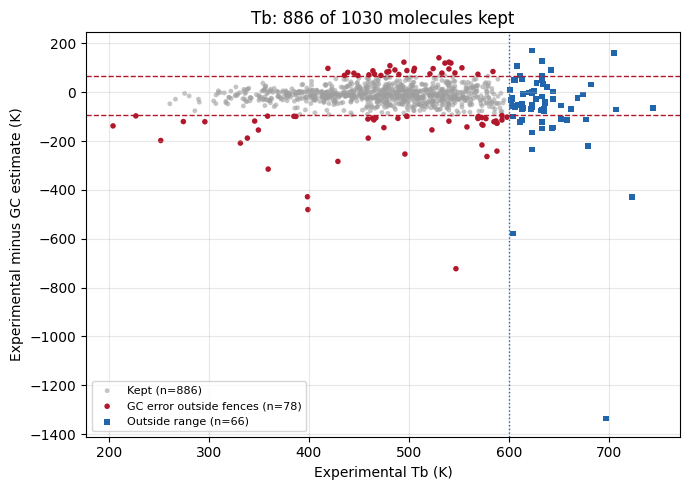

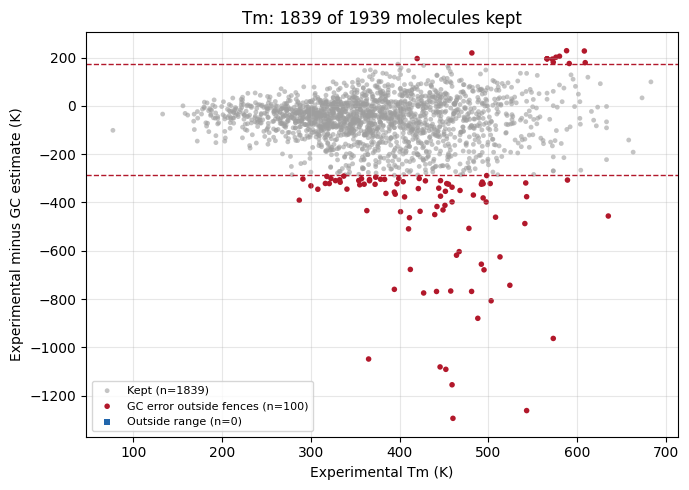

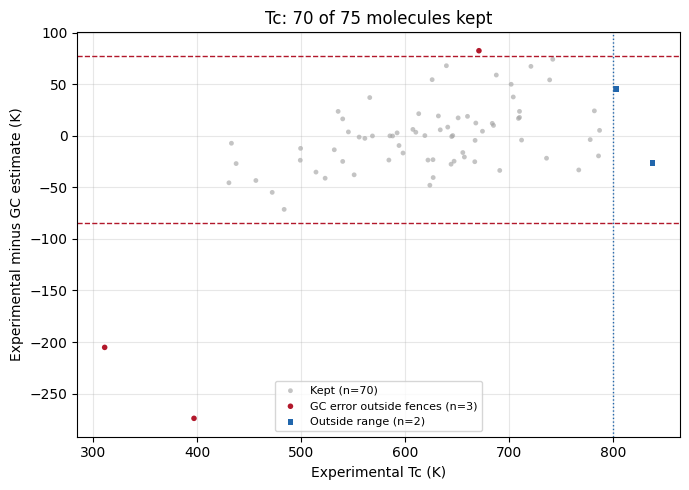

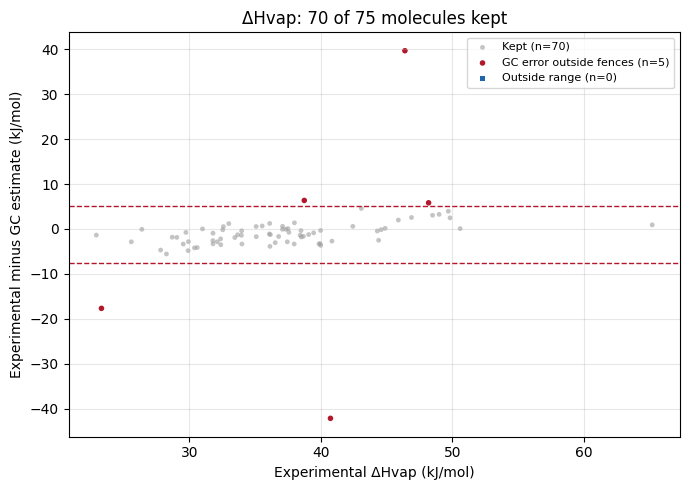

In [5]:
for code in [c for c in PROPERTY_ORDER if SELECTED_VERSION[c] == "noOutlier"]:
    plotCuration(code, savePath=CURATED_DATA_DIR / f"curation_{code}.png")

### 4.3 Dataset sizes

The number of molecules in each curated dataset, which is the number used by
every modelling notebook.

In [6]:
summaryDf[["Property", "Rows_in_file", "Usable_rows", "Curated_rows"]].rename(columns={
    "Rows_in_file": "Entries in input file", "Usable_rows": "Usable entries", "Curated_rows": "Curated dataset"})

,Property,Entries in input file,Usable entries,Curated dataset
0,Tb,1030,1030,886
1,Tm,1939,1939,1839
2,Pc,75,75,75
3,Vc,69,69,69
4,Tc,75,75,70
5,Hvap,75,75,70
6,logP,3536,3463,2978


## 5. Summary of the results

Written from the curation summary of this run and saved as
`Output_Data/curated_data/results_summary.md`.

In [7]:
from gcgp.narrative import describeCuration, showAndSave

showAndSave(describeCuration(summaryDf), CURATED_DATA_DIR / "results_summary.md");

## Data curation: results

- **Tb**: 1030 usable entries of 1030 in the input file; removed: 66 with an experimental value outside [0, 600] K; 78 with a GC error outside the 1.5 × IQR fences [-94.332, 68.507]. Curated dataset: 886 molecules.
- **Tm**: 1939 usable entries of 1939 in the input file; removed: 100 with a GC error outside the 1.5 × IQR fences [-287.245, 174.555]. Curated dataset: 1839 molecules.
- **Pc**: 75 usable entries of 75 in the input file; all usable molecules kept. Curated dataset: 75 molecules.
- **Vc**: 69 usable entries of 69 in the input file; all usable molecules kept. Curated dataset: 69 molecules.
- **Tc**: 75 usable entries of 75 in the input file; removed: 2 with an experimental value outside [0, 800] K; 3 with a GC error outside the 1.5 × IQR fences [-84.525, 77.748]. Curated dataset: 70 molecules.
- **ΔHvap**: 75 usable entries of 75 in the input file; removed: 5 with a GC error outside the 1.5 × IQR fences [-7.647, 5.120]. Curated dataset: 70 molecules.
- **log P**: 3463 usable entries of 3536 in the input file; removed: 485 repeated entries of a structure already in the set. Curated dataset: 2978 molecules.
